In [7]:
# Project: Retail KPI Dictionary & Data Quality Contract
# Purpose: Data profiling, validation, KPI analysis, and reporting

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Professional notebook display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

# Locate project root flexibly (whether running from root or notebooks/)
def get_project_root():
    cwd = Path.cwd()
    if (cwd / "data").is_dir() or (cwd / "Dataset").is_dir() or (cwd / "README.md").is_file():
        return cwd
    if (cwd.parent / "data").is_dir() or (cwd.parent / "Dataset").is_dir() or (cwd.parent / "README.md").is_file():
        return cwd.parent
    return cwd

PROJECT_DIR = get_project_root()
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHART_DIR = OUTPUT_DIR / "charts"
REPORT_DIR = PROJECT_DIR / "documentation"

for folder in [OUTPUT_DIR, CHART_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project initialized successfully.")
print("Notebook directory:", Path.cwd().resolve())
print("Project root:      ", PROJECT_DIR.resolve())
print("Output directory:  ", OUTPUT_DIR.resolve())


Project initialized successfully.
Notebook directory: C:\Users\gurus\Music
Output directory: C:\Users\gurus\Music\outputs


In [9]:
# Locate the input files flexibly
possible_locations = [
    PROJECT_DIR / "data",
    PROJECT_DIR / "Dataset",
    PROJECT_DIR,
    Path.cwd() / "data",
    Path.cwd() / "Dataset",
    Path.cwd(),
]

def locate_file(filename):
    target_name = Path(filename).name
    for folder in possible_locations:
        candidate = folder / target_name
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot find '{filename}'. "
        "Place the file in data/ or beside your notebook."
    )

orders_path = locate_file("retail-orders-raw.csv")
dictionary_path = locate_file("retail-data-dictionary.csv")

# Load CSVs as provided; preserve raw values for quality assessment
orders_raw = pd.read_csv(orders_path)
data_dictionary = pd.read_csv(dictionary_path)

print("Both datasets loaded successfully.")
print(f"Orders dataset: {orders_raw.shape[0]} rows × {orders_raw.shape[1]} columns")
print(f"Dictionary:     {data_dictionary.shape[0]} rows × {data_dictionary.shape[1]} columns")


Both datasets loaded successfully.
Orders dataset: 12 rows × 9 columns
Dictionary:     9 rows × 4 columns


In [10]:

# ============================================================
# STEP 3: DATASET EXPLORATION
# ============================================================

print("=" * 60)
print("RETAIL ORDERS DATASET")
print("=" * 60)

# Display all column names
print("\nColumn names:")
print(orders_raw.columns.tolist())

# Display first five records
print("\nFirst five records:")
display(orders_raw.head())

# Inspect column data types and non-null counts
print("\nDataset information:")
orders_raw.info()

# Check dataset dimensions
print("\nDataset dimensions:")
print(f"Rows    : {orders_raw.shape[0]}")
print(f"Columns : {orders_raw.shape[1]}")

# Inspect the data dictionary
print("\n" + "=" * 60)
print("DATA DICTIONARY")
print("=" * 60)

display(data_dictionary)


RETAIL ORDERS DATASET

Column names:
['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']

First five records:


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.00,Paid
1,RT-1002,03/01/2026,Fresher,Bengaluru,Course Access,1,1499,0.00,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1,1499,NaN,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.00,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.00,Paid



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          12 non-null     object 
 1   order_date        11 non-null     object 
 2   customer_segment  12 non-null     object 
 3   city              11 non-null     object 
 4   category          12 non-null     object 
 5   quantity          12 non-null     object 
 6   unit_price        12 non-null     int64  
 7   discount_pct      11 non-null     float64
 8   payment_status    12 non-null     object 
dtypes: float64(1), int64(1), object(7)
memory usage: 996.0+ bytes

Dataset dimensions:
Rows    : 12
Columns : 9

DATA DICTIONARY


,column,data_type,business_definition,quality_rule
0,order_id,string,Unique order identifier,Required and unique
1,order_date,date,Date the customer placed the order,Required ISO date between 2025-01-01 and today
2,customer_segment,category,Commercial customer segment,Student Fresher or Professional after normaliz...
3,city,string,Customer billing city,Required non-empty text
4,category,category,Product family,Learning Kit Course Access or Mentor Session
5,quantity,integer,Units purchased,Whole number greater than zero
6,unit_price,decimal,Price per unit before discount,Non-negative INR amount
7,discount_pct,decimal,Percentage discount applied,Between 0 and 100; missing means zero only aft...
8,payment_status,category,Latest order settlement state,Paid Pending Failed or Refunded after normaliz...


In [11]:

# ============================================================
# STEP 4: INITIAL DATA QUALITY ASSESSMENT
# ============================================================

# Missing values by column
missing_summary = pd.DataFrame({
    "column": orders_raw.columns,
    "missing_count": [
        orders_raw[col].isna().sum()
        for col in orders_raw.columns
    ],
    "completeness_pct": [
        round(orders_raw[col].notna().mean() * 100, 2)
        for col in orders_raw.columns
    ]
})

print("MISSING VALUE SUMMARY")
display(missing_summary)

# Duplicate rows
duplicate_rows = orders_raw.duplicated().sum()

print(f"\nExact duplicate rows: {duplicate_rows}")

# Duplicate order IDs
if "order_id" in orders_raw.columns:
    duplicate_order_ids = orders_raw[
        orders_raw["order_id"].duplicated(keep=False)
    ].sort_values("order_id")

    print("\nDUPLICATE ORDER IDs")
    display(duplicate_order_ids)

# Save initial findings
missing_summary.to_csv(
    OUTPUT_DIR / "missing_value_summary.csv",
    index=False
)

print("\nMissing-value report saved successfully.")


MISSING VALUE SUMMARY


,column,missing_count,completeness_pct
0,order_id,0,100.00
1,order_date,1,91.67
2,customer_segment,0,100.00
3,city,1,91.67
4,category,0,100.00
5,quantity,0,100.00
6,unit_price,0,100.00
7,discount_pct,1,91.67
8,payment_status,0,100.00



Exact duplicate rows: 1

DUPLICATE ORDER IDs


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.00,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.00,Paid



Missing-value report saved successfully.


DATA PROFILE


,column,data_type,total_records,missing_values,completeness_pct,unique_values
0,order_id,object,12,0,100.00,11
1,order_date,object,12,1,91.67,10
2,customer_segment,object,12,0,100.00,4
3,city,object,12,1,91.67,7
4,category,object,12,0,100.00,3
5,quantity,object,12,0,100.00,5
6,unit_price,int64,12,0,100.00,3
7,discount_pct,float64,12,1,91.67,5
8,payment_status,object,12,0,100.00,5


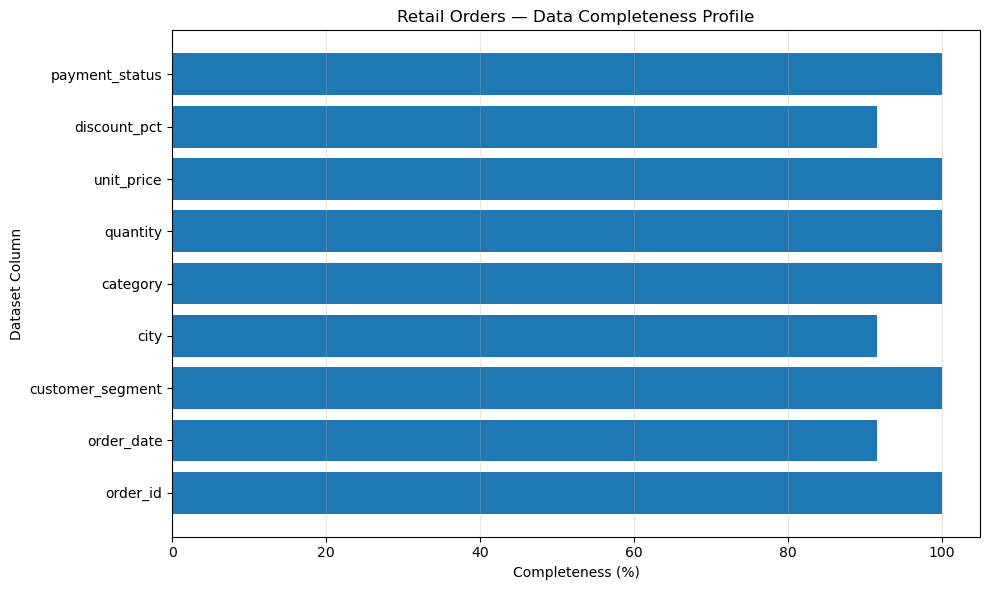

Profile and chart saved successfully.


In [12]:

# ============================================================
# STEP 5: DATA PROFILING AND VISUALIZATION
# ============================================================

profile = pd.DataFrame({
    "column": orders_raw.columns,
    "data_type": [
        str(orders_raw[col].dtype)
        for col in orders_raw.columns
    ],
    "total_records": len(orders_raw),
    "missing_values": [
        orders_raw[col].isna().sum()
        for col in orders_raw.columns
    ],
    "completeness_pct": [
        round(orders_raw[col].notna().mean() * 100, 2)
        for col in orders_raw.columns
    ],
    "unique_values": [
        orders_raw[col].nunique(dropna=True)
        for col in orders_raw.columns
    ]
})

print("DATA PROFILE")
display(profile)

# Export the profile
profile.to_csv(
    OUTPUT_DIR / "initial_data_profile.csv",
    index=False
)

# Plot completeness
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    profile["column"],
    profile["completeness_pct"]
)

ax.set_title("Retail Orders — Data Completeness Profile")
ax.set_xlabel("Completeness (%)")
ax.set_ylabel("Dataset Column")
ax.set_xlim(0, 105)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

fig.savefig(
    CHART_DIR / "data_completeness.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Profile and chart saved successfully.")


In [13]:

# ============================================================
# STEP 6: DATA QUALITY VALIDATION ENGINE
# Project: Retail KPI Dictionary & Data Quality Contract
# ============================================================

# Create a working copy; never modify the raw dataset
orders_check = orders_raw.copy()

# Standardize whitespace in text fields on the working copy
text_columns = orders_check.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    orders_check[col] = orders_check[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Parse dates and numeric values safely
orders_check["parsed_order_date"] = pd.to_datetime(
    orders_check["order_date"],
    format="mixed",
    errors="coerce"
)

orders_check["numeric_quantity"] = pd.to_numeric(
    orders_check["quantity"],
    errors="coerce"
)

orders_check["numeric_unit_price"] = pd.to_numeric(
    orders_check["unit_price"],
    errors="coerce"
)

orders_check["numeric_discount"] = pd.to_numeric(
    orders_check["discount_pct"],
    errors="coerce"
)

# Store all detected issues in one structured report
quality_issues = []

def record_issues(mask, column, rule, severity="Error"):
    """Record rows that violate a data quality rule."""
    mask = pd.Series(mask, index=orders_check.index)
    mask = mask.fillna(False).astype(bool)

    for idx in orders_check.index[mask]:
        quality_issues.append({
            "row_index": idx,
            "order_id": orders_check.loc[idx, "order_id"],
            "column": column,
            "rule": rule,
            "severity": severity,
            "observed_value": str(orders_check.loc[idx, column])
        })

# Rule 1: Required fields must not be missing
required_columns = [
    "order_id",
    "order_date",
    "customer_segment",
    "city",
    "category",
    "quantity",
    "unit_price",
    "payment_status"
]

for col in required_columns:
    missing_mask = orders_check[col].isna()

    if pd.api.types.is_object_dtype(orders_check[col]) or \
       pd.api.types.is_string_dtype(orders_check[col]):
        missing_mask = (
            missing_mask |
            orders_check[col].astype("string").str.strip().eq("").fillna(False)
        )

    record_issues(missing_mask, col, "Required field is missing")

# Rule 2: Order IDs must be unique
record_issues(
    orders_check["order_id"].duplicated(keep=False),
    "order_id",
    "Duplicate order ID"
)

# Rule 3: Order dates must be valid
record_issues(
    orders_check["parsed_order_date"].isna(),
    "order_date",
    "Missing or invalid date"
)

# Rule 4: Quantity must be numeric
record_issues(
    orders_check["numeric_quantity"].isna(),
    "quantity",
    "Quantity must be numeric"
)

# Rule 5: Quantity must be positive
record_issues(
    orders_check["numeric_quantity"].notna() &
    (orders_check["numeric_quantity"] <= 0),
    "quantity",
    "Quantity must be greater than zero"
)

# Rule 6: Quantity must be a whole number
record_issues(
    orders_check["numeric_quantity"].notna() &
    (orders_check["numeric_quantity"] % 1 != 0),
    "quantity",
    "Quantity must be a whole number"
)

# Rule 7: Unit price must be numeric and non-negative
record_issues(
    orders_check["numeric_unit_price"].isna(),
    "unit_price",
    "Unit price must be numeric"
)

record_issues(
    orders_check["numeric_unit_price"].notna() &
    (orders_check["numeric_unit_price"] < 0),
    "unit_price",
    "Unit price must be non-negative"
)

# Rule 8: Discount must be between 0 and 100
record_issues(
    orders_check["numeric_discount"].notna() &
    ~orders_check["numeric_discount"].between(0, 100),
    "discount_pct",
    "Discount must be between 0 and 100"
)

# Missing discounts are flagged separately for review
record_issues(
    orders_check["numeric_discount"].isna(),
    "discount_pct",
    "Discount missing or non-numeric",
    severity="Review"
)

# Rule 9: Validate payment status
allowed_statuses = {
    "paid", "pending", "failed", "refunded"
}

record_issues(
    ~orders_check["payment_status"].str.lower().isin(allowed_statuses),
    "payment_status",
    "Unrecognized payment status"
)

# Rule 10: Validate customer segments
allowed_segments = {
    "student", "fresher", "professional"
}

record_issues(
    ~orders_check["customer_segment"].str.lower().isin(allowed_segments),
    "customer_segment",
    "Unrecognized customer segment"
)

# Rule 11: Category must be populated
record_issues(
    orders_check["category"].isna() |
    orders_check["category"].eq(""),
    "category",
    "Category is missing"
)

# Convert findings into a DataFrame
quality_issues_df = pd.DataFrame(
    quality_issues,
    columns=[
        "row_index",
        "order_id",
        "column",
        "rule",
        "severity",
        "observed_value"
    ]
)

# Display and save findings
print("Total individual quality violations:", len(quality_issues_df))

display(
    quality_issues_df.sort_values(
        ["severity", "column", "row_index"]
    )
)

quality_issues_df.to_csv(
    OUTPUT_DIR / "data_quality_issues.csv",
    index=False
)

print("Quality issues saved to:", (OUTPUT_DIR / "data_quality_issues.csv").resolve())


Total individual quality violations: 10


,row_index,order_id,column,rule,severity,observed_value
1,5,RT-1005,city,Required field is missing,Error,nan
8,7,RT-1007,discount_pct,Discount must be between 0 and 100,Error,105.0
4,6,RT-1006,order_date,Missing or invalid date,Error,2026-13-10
0,11,RT-1011,order_date,Required field is missing,Error,nan
5,11,RT-1011,order_date,Missing or invalid date,Error,nan
2,3,RT-1004,order_id,Duplicate order ID,Error,RT-1004
3,4,RT-1004,order_id,Duplicate order ID,Error,RT-1004
7,6,RT-1006,quantity,Quantity must be greater than zero,Error,-1
6,8,RT-1008,quantity,Quantity must be numeric,Error,two
9,2,RT-1003,discount_pct,Discount missing or non-numeric,Review,nan


Quality issues saved to: C:\Users\gurus\Music\outputs\data_quality_issues.csv


In [14]:

# ============================================================
# STEP 7: QUALITY ISSUE SUMMARY
# ============================================================

if not quality_issues_df.empty:

    issue_summary = (
        quality_issues_df
        .groupby(["column", "rule", "severity"])
        .size()
        .reset_index(name="issue_count")
        .sort_values("issue_count", ascending=False)
    )

    display(issue_summary)

    issue_summary.to_csv(
        OUTPUT_DIR / "quality_issue_summary.csv",
        index=False
    )

    print("Summary saved successfully.")

else:
    issue_summary = pd.DataFrame(
        columns=["column", "rule", "severity", "issue_count"]
    )
    print("No quality violations were detected.")


,column,rule,severity,issue_count
3,order_date,Missing or invalid date,Error,2
5,order_id,Duplicate order ID,Error,2
1,discount_pct,Discount missing or non-numeric,Review,1
0,city,Required field is missing,Error,1
2,discount_pct,Discount must be between 0 and 100,Error,1
4,order_date,Required field is missing,Error,1
6,quantity,Quantity must be greater than zero,Error,1
7,quantity,Quantity must be numeric,Error,1


Summary saved successfully.


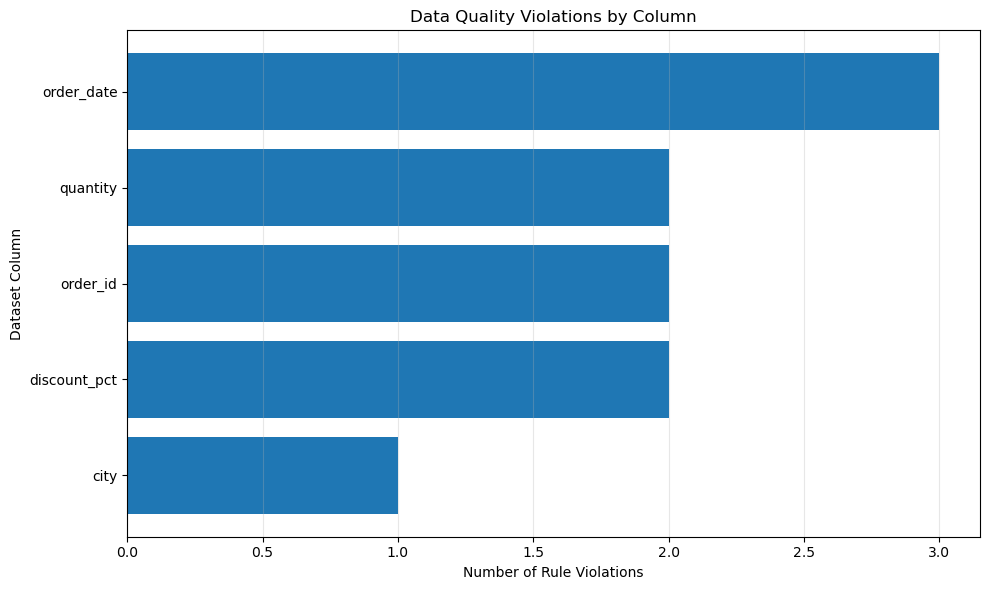

Chart saved successfully.


In [15]:

# ============================================================
# STEP 8: DATA QUALITY FAILURE CHART
# ============================================================

if not quality_issues_df.empty:

    violations_by_column = (
        quality_issues_df
        .groupby("column")
        .size()
        .sort_values()
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.barh(
        violations_by_column.index,
        violations_by_column.values
    )

    ax.set_title("Data Quality Violations by Column")
    ax.set_xlabel("Number of Rule Violations")
    ax.set_ylabel("Dataset Column")
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()

    fig.savefig(
        CHART_DIR / "data_quality_violations.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print("Chart saved successfully.")

else:
    print("No violations available to visualize.")


In [16]:

# ============================================================
# STEP 9: PREPARE ANALYSIS-READY DATA
# ============================================================

analysis_data = orders_raw.copy()

# Standardize whitespace in text columns
for col in analysis_data.select_dtypes(
    include=["object", "string"]
).columns:
    analysis_data[col] = analysis_data[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Normalize capitalization for categorical fields
analysis_data["customer_segment"] = (
    analysis_data["customer_segment"].str.title()
)

analysis_data["payment_status"] = (
    analysis_data["payment_status"].str.title()
)

# Convert dates and numeric fields safely
analysis_data["order_date"] = pd.to_datetime(
    analysis_data["order_date"],
    format="mixed",
    errors="coerce"
)

analysis_data["quantity"] = pd.to_numeric(
    analysis_data["quantity"], errors="coerce"
)

analysis_data["unit_price"] = pd.to_numeric(
    analysis_data["unit_price"], errors="coerce"
)

analysis_data["discount_pct"] = pd.to_numeric(
    analysis_data["discount_pct"], errors="coerce"
)

# Validation flags
analysis_data["duplicate_order_id"] = (
    analysis_data["order_id"].duplicated(keep=False)
)

analysis_data["valid_date"] = (
    analysis_data["order_date"].notna()
)

analysis_data["valid_quantity"] = (
    analysis_data["quantity"].notna()
    & (analysis_data["quantity"] > 0)
    & (analysis_data["quantity"] % 1 == 0)
)

analysis_data["valid_unit_price"] = (
    analysis_data["unit_price"].notna()
    & (analysis_data["unit_price"] >= 0)
)

analysis_data["valid_discount"] = (
    analysis_data["discount_pct"].notna()
    & analysis_data["discount_pct"].between(0, 100)
)

analysis_data["eligible_for_value_analysis"] = (
    ~analysis_data["duplicate_order_id"]
    & analysis_data["valid_date"]
    & analysis_data["valid_quantity"]
    & analysis_data["valid_unit_price"]
    & analysis_data["valid_discount"]
)

print("Analysis dataset prepared.")
print("Original rows:", len(orders_raw))
print("Analysis rows:", len(analysis_data))
print(
    "Eligible for value analysis:",
    int(analysis_data["eligible_for_value_analysis"].sum())
)

display(analysis_data.head(10))

analysis_data.to_csv(
    OUTPUT_DIR / "retail_orders_analysis_ready.csv",
    index=False
)


Analysis dataset prepared.
Original rows: 12
Analysis rows: 12
Eligible for value analysis: 5


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,duplicate_order_id,valid_date,valid_quantity,valid_unit_price,valid_discount,eligible_for_value_analysis
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2.00,799,10.00,Paid,False,True,True,True,True,True
1,RT-1002,2026-03-01,Fresher,Bengaluru,Course Access,1.00,1499,0.00,Paid,False,True,True,True,True,True
2,RT-1003,2026-01-05,Student,Chennai,Course Access,1.00,1499,NaN,Pending,False,True,True,True,False,False
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.00,799,5.00,Paid,True,True,True,True,True,False
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.00,799,5.00,Paid,True,True,True,True,True,False
5,RT-1005,2026-01-09,Fresher,NaN,Mentor Session,1.00,999,0.00,Failed,False,True,True,True,True,True
6,RT-1006,NaT,Student,Pune,Learning Kit,-1.00,799,10.00,Paid,False,False,False,True,True,False
7,RT-1007,2026-01-12,Professional,Mumbai,Mentor Session,2.00,999,105.00,Paid,False,True,True,True,False,False
8,RT-1008,2026-01-14,Fresher,Bengaluru,Course Access,NaN,1499,0.00,Pending,False,True,False,True,True,False
9,RT-1009,2026-01-16,Student,Chennai,Learning Kit,1.00,799,0.00,Paid,False,True,True,True,True,True


In [17]:

# ============================================================
# STEP 10: KPI CALCULATION
# ============================================================

kpi_data = analysis_data.loc[
    analysis_data["eligible_for_value_analysis"]
].copy()

# Calculate estimated order values
kpi_data["gross_order_value_estimate"] = (
    kpi_data["quantity"] * kpi_data["unit_price"]
)

kpi_data["discount_amount_estimate"] = (
    kpi_data["gross_order_value_estimate"]
    * kpi_data["discount_pct"] / 100
)

kpi_data["net_order_value_estimate"] = (
    kpi_data["gross_order_value_estimate"]
    - kpi_data["discount_amount_estimate"]
)

# Payment status counts
status = kpi_data["payment_status"].str.lower()

paid_count = int(status.eq("paid").sum())
pending_count = int(status.eq("pending").sum())
failed_count = int(status.eq("failed").sum())
refunded_count = int(status.eq("refunded").sum())

total_status_orders = paid_count + pending_count + failed_count + refunded_count

failed_payment_rate = (
    failed_count / total_status_orders * 100
    if total_status_orders else np.nan
)

refunded_order_rate = (
    refunded_count / total_status_orders * 100
    if total_status_orders else np.nan
)

# Build KPI results
kpi_results = pd.DataFrame([
    {
        "KPI": "Eligible unique orders",
        "Value": len(kpi_data),
        "Unit": "orders"
    },
    {
        "KPI": "Paid orders",
        "Value": paid_count,
        "Unit": "orders"
    },
    {
        "KPI": "Pending orders",
        "Value": pending_count,
        "Unit": "orders"
    },
    {
        "KPI": "Failed orders",
        "Value": failed_count,
        "Unit": "orders"
    },
    {
        "KPI": "Refunded orders",
        "Value": refunded_count,
        "Unit": "orders"
    },
    {
        "KPI": "Failed payment rate",
        "Value": round(failed_payment_rate, 2),
        "Unit": "%"
    },
    {
        "KPI": "Refunded order rate",
        "Value": round(refunded_order_rate, 2),
        "Unit": "%"
    },
    {
        "KPI": "Gross order value estimate",
        "Value": kpi_data["gross_order_value_estimate"].sum(),
        "Unit": "currency units"
    },
    {
        "KPI": "Discount amount estimate",
        "Value": kpi_data["discount_amount_estimate"].sum(),
        "Unit": "currency units"
    },
    {
        "KPI": "Net order value estimate",
        "Value": kpi_data["net_order_value_estimate"].sum(),
        "Unit": "currency units"
    },
    {
        "KPI": "Average net order value estimate",
        "Value": kpi_data["net_order_value_estimate"].mean(),
        "Unit": "currency units/order"
    }
])

display(kpi_results)

kpi_results.to_csv(
    OUTPUT_DIR / "preliminary_kpi_results.csv",
    index=False
)

print("KPI results saved successfully.")


,KPI,Value,Unit
0,Eligible unique orders,5.00,orders
1,Paid orders,3.00,orders
2,Pending orders,0.00,orders
3,Failed orders,1.00,orders
4,Refunded orders,1.00,orders
5,Failed payment rate,20.00,%
6,Refunded order rate,20.00,%
7,Gross order value estimate,"7,893.00",currency units
8,Discount amount estimate,609.50,currency units
9,Net order value estimate,"7,283.50",currency units


KPI results saved successfully.


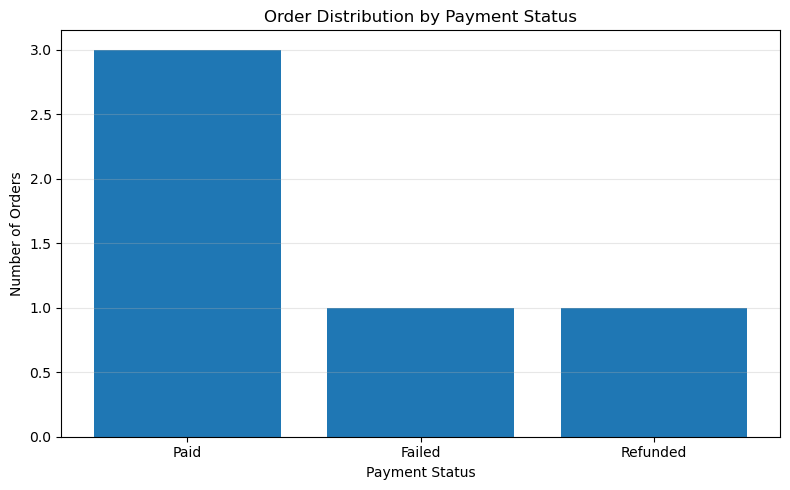

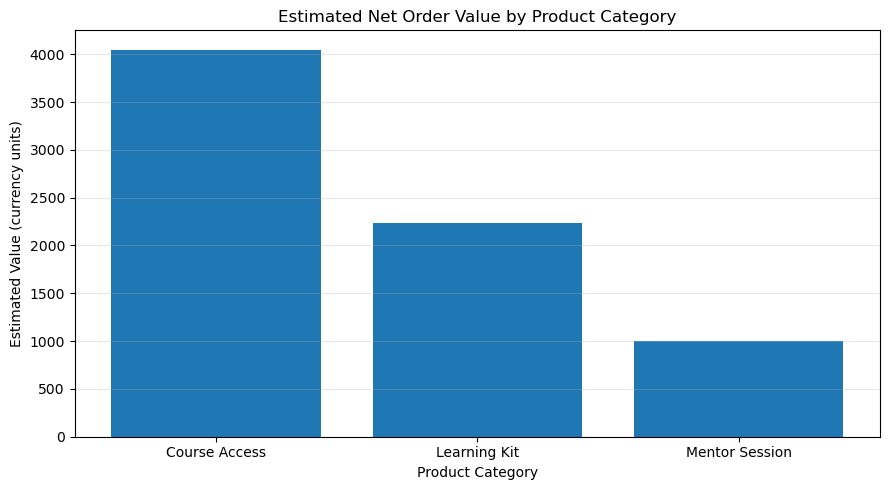

,KPI,Value,Unit
0,Eligible unique orders,5.00,orders
1,Paid orders,3.00,orders
2,Pending orders,0.00,orders
3,Failed orders,1.00,orders
4,Refunded orders,1.00,orders
5,Failed payment rate,20.00,%
6,Refunded order rate,20.00,%
7,Gross order value estimate,"7,893.00",currency units
8,Discount amount estimate,609.50,currency units
9,Net order value estimate,"7,283.50",currency units


In [18]:

# ============================================================
# STEP 11: BUSINESS KPI VISUALIZATIONS
# ============================================================

# Chart 1: Payment status distribution
status_counts = kpi_data["payment_status"].str.title().value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(status_counts.index, status_counts.values)

ax.set_title("Order Distribution by Payment Status")
ax.set_xlabel("Payment Status")
ax.set_ylabel("Number of Orders")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(
    CHART_DIR / "payment_status_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# Chart 2: Estimated net order value by category
category_values = (
    kpi_data.groupby("category")["net_order_value_estimate"]
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(category_values.index, category_values.values)

ax.set_title("Estimated Net Order Value by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Estimated Value (currency units)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(
    CHART_DIR / "net_order_value_by_category.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# Chart 3: KPI values table for quick reporting
display(kpi_results)


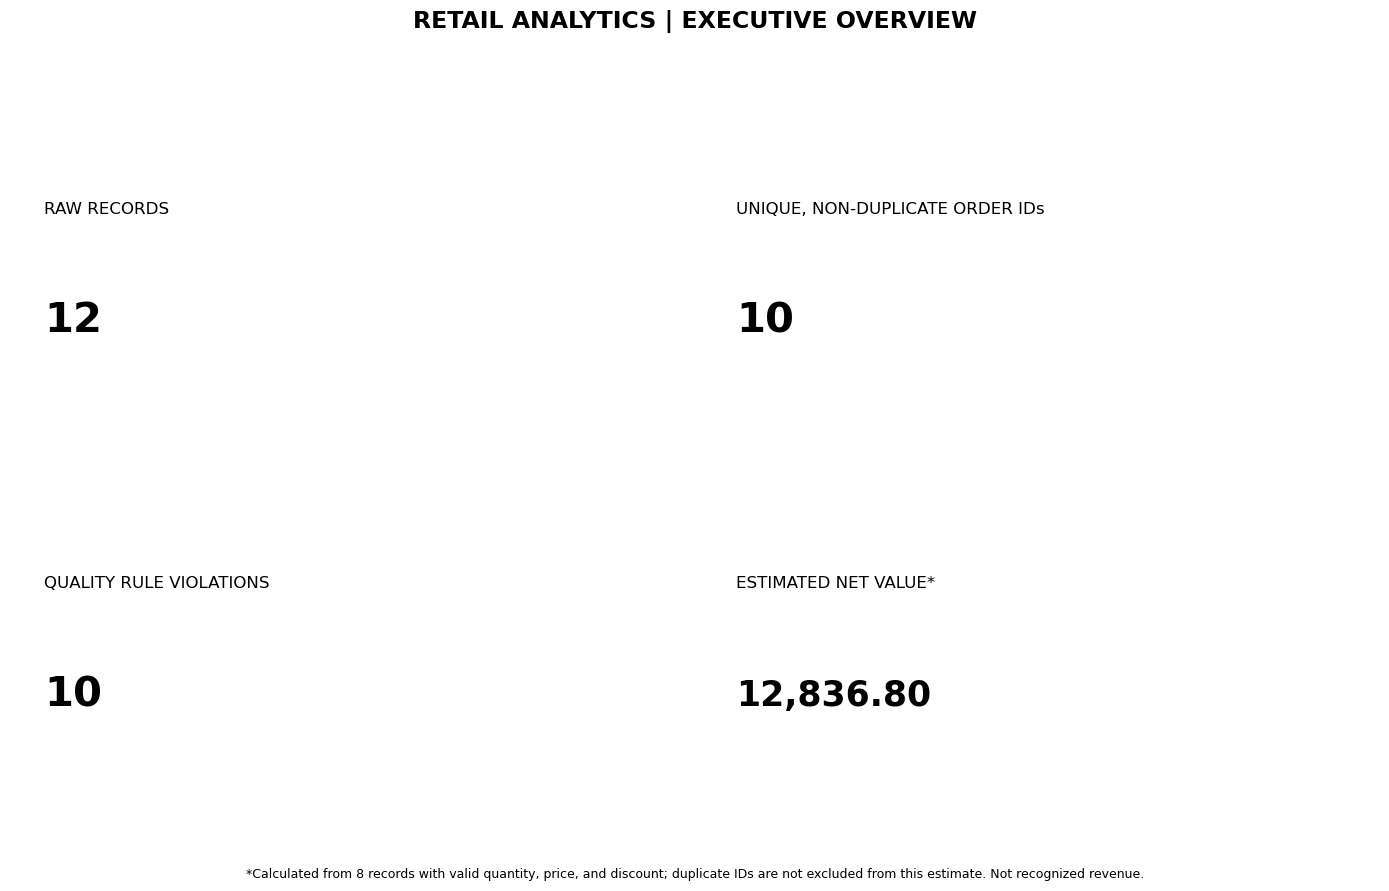

In [24]:

# ============================================================
# VISUALIZATION 1: EXECUTIVE KPI DASHBOARD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path

CHART_DIR = OUTPUT_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

df = orders_raw.copy()

# Safely derive numerical fields for visualization
df["quantity_num"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price_num"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["discount_num"] = pd.to_numeric(df["discount_pct"], errors="coerce")

valid_value = (
    df["quantity_num"].gt(0)
    & df["quantity_num"].notna()
    & (df["quantity_num"] % 1 == 0)
    & df["price_num"].ge(0)
    & df["price_num"].notna()
    & df["discount_num"].between(0, 100)
)

df["estimated_net_value"] = (
    df["quantity_num"] * df["price_num"]
    * (1 - df["discount_num"] / 100)
)

# Exclude duplicate IDs from the headline unique-order metric
unique_order_mask = (
    df["order_id"].notna()
    & ~df["order_id"].duplicated(keep=False)
)

total_unique_orders = int(unique_order_mask.sum())
quality_issue_count = len(quality_issues_df)
valid_value_records = int(valid_value.sum())

total_estimated_value = df.loc[
    valid_value, "estimated_net_value"
].sum()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    "RETAIL ANALYTICS | EXECUTIVE OVERVIEW",
    fontsize=17,
    fontweight="bold"
)

# KPI cards
axes[0, 0].axis("off")
axes[0, 0].text(
    0.05, 0.68, "RAW RECORDS",
    fontsize=12, transform=axes[0, 0].transAxes
)
axes[0, 0].text(
    0.05, 0.35, f"{len(df)}",
    fontsize=30, fontweight="bold",
    transform=axes[0, 0].transAxes
)

axes[0, 1].axis("off")
axes[0, 1].text(
    0.05, 0.68, "UNIQUE, NON-DUPLICATE ORDER IDs",
    fontsize=12, transform=axes[0, 1].transAxes
)
axes[0, 1].text(
    0.05, 0.35, f"{total_unique_orders}",
    fontsize=30, fontweight="bold",
    transform=axes[0, 1].transAxes
)

axes[1, 0].axis("off")
axes[1, 0].text(
    0.05, 0.68, "QUALITY RULE VIOLATIONS",
    fontsize=12, transform=axes[1, 0].transAxes
)
axes[1, 0].text(
    0.05, 0.35, f"{quality_issue_count}",
    fontsize=30, fontweight="bold",
    transform=axes[1, 0].transAxes
)

axes[1, 1].axis("off")
axes[1, 1].text(
    0.05, 0.68, "ESTIMATED NET VALUE*",
    fontsize=12, transform=axes[1, 1].transAxes
)
axes[1, 1].text(
    0.05, 0.35, f"{total_estimated_value:,.2f}",
    fontsize=25, fontweight="bold",
    transform=axes[1, 1].transAxes
)

fig.text(
    0.5, 0.015,
    f"*Calculated from {valid_value_records} records with valid quantity, price, and discount; "
    "duplicate IDs are not excluded from this estimate. Not recognized revenue.",
    ha="center", fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.savefig(
    CHART_DIR / "executive_kpi_dashboard.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


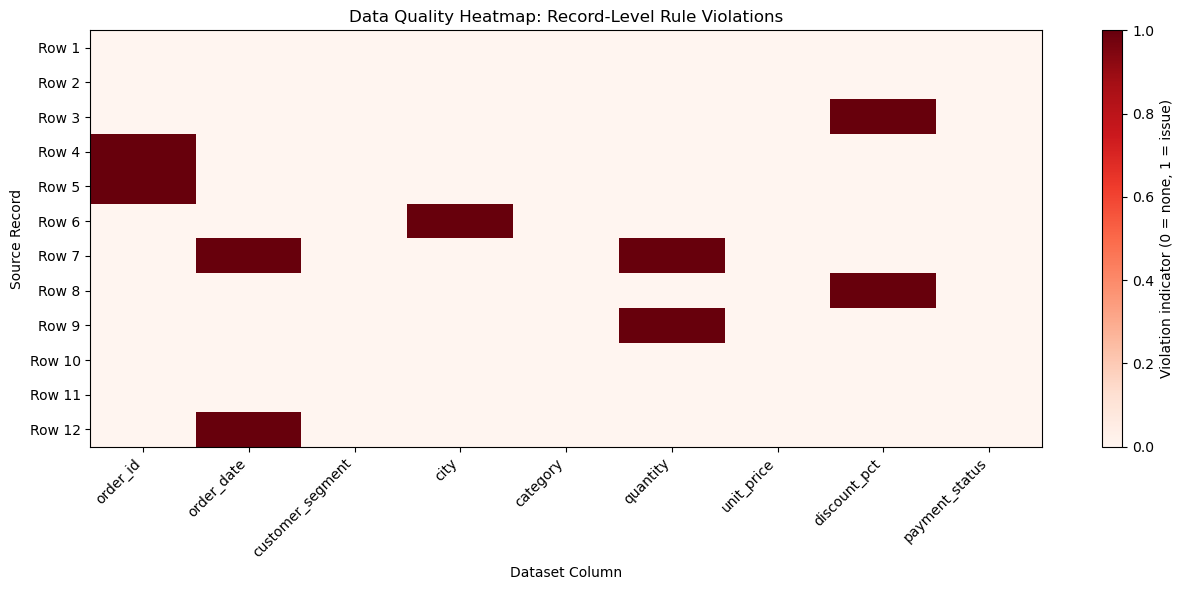

In [25]:

# ============================================================
# VISUALIZATION 2: DATA QUALITY HEATMAP
# ============================================================

quality_columns = [
    "order_id", "order_date", "customer_segment",
    "city", "category", "quantity",
    "unit_price", "discount_pct", "payment_status"
]

# Build a row-by-column issue matrix
issue_matrix = pd.DataFrame(
    0,
    index=orders_raw.index,
    columns=quality_columns
)

if not quality_issues_df.empty:
    for _, issue in quality_issues_df.iterrows():
        row_idx = issue["row_index"]
        col_name = issue["column"]

        if row_idx in issue_matrix.index and col_name in issue_matrix.columns:
            issue_matrix.loc[row_idx, col_name] = 1

fig, ax = plt.subplots(figsize=(13, 6))

image = ax.imshow(
    issue_matrix.values,
    aspect="auto",
    interpolation="nearest",
    cmap="Reds",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(issue_matrix.columns)))
ax.set_xticklabels(issue_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(issue_matrix.index)))
ax.set_yticklabels([f"Row {i + 1}" for i in issue_matrix.index])

ax.set_title("Data Quality Heatmap: Record-Level Rule Violations")
ax.set_xlabel("Dataset Column")
ax.set_ylabel("Source Record")

fig.colorbar(image, ax=ax, label="Violation indicator (0 = none, 1 = issue)")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "data_quality_heatmap.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


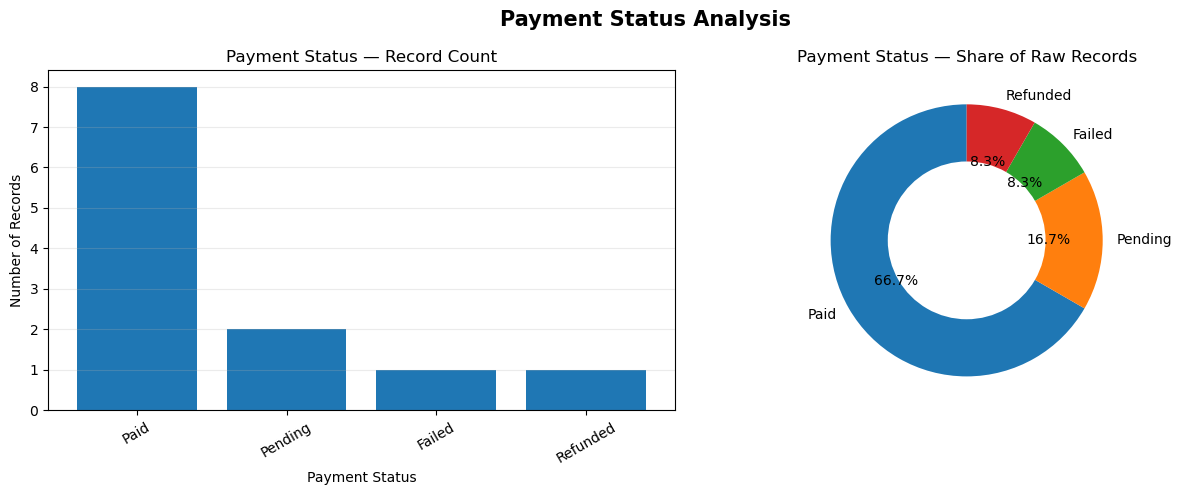

In [26]:

# ============================================================
# VISUALIZATION 3: PAYMENT STATUS DISTRIBUTION
# ============================================================

status_counts = (
    df["payment_status"]
    .fillna("Missing")
    .astype(str)
    .str.strip()
    .str.title()
    .value_counts()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(status_counts.index, status_counts.values)
axes[0].set_title("Payment Status — Record Count")
axes[0].set_xlabel("Payment Status")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.25)

axes[1].pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)
axes[1].set_title("Payment Status — Share of Raw Records")

fig.suptitle("Payment Status Analysis", fontsize=15, fontweight="bold")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "payment_status_analysis.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


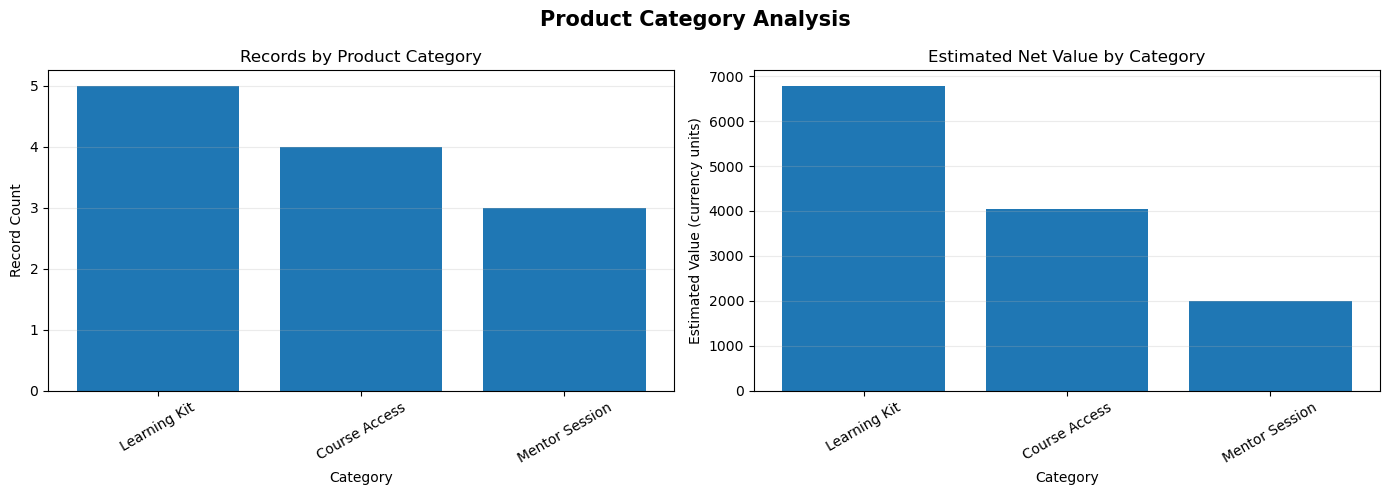

In [27]:

# ============================================================
# VISUALIZATION 4: CATEGORY PERFORMANCE
# ============================================================

category_counts = (
    df["category"].fillna("Missing").value_counts()
)

category_value_data = df.loc[
    valid_value & df["category"].notna()
].copy()

category_values = (
    category_value_data.groupby("category")["estimated_net_value"]
    .sum()
    .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(category_counts.index, category_counts.values)
axes[0].set_title("Records by Product Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Record Count")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(category_values.index, category_values.values)
axes[1].set_title("Estimated Net Value by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Estimated Value (currency units)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Product Category Analysis", fontsize=15, fontweight="bold")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "category_performance_dashboard.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


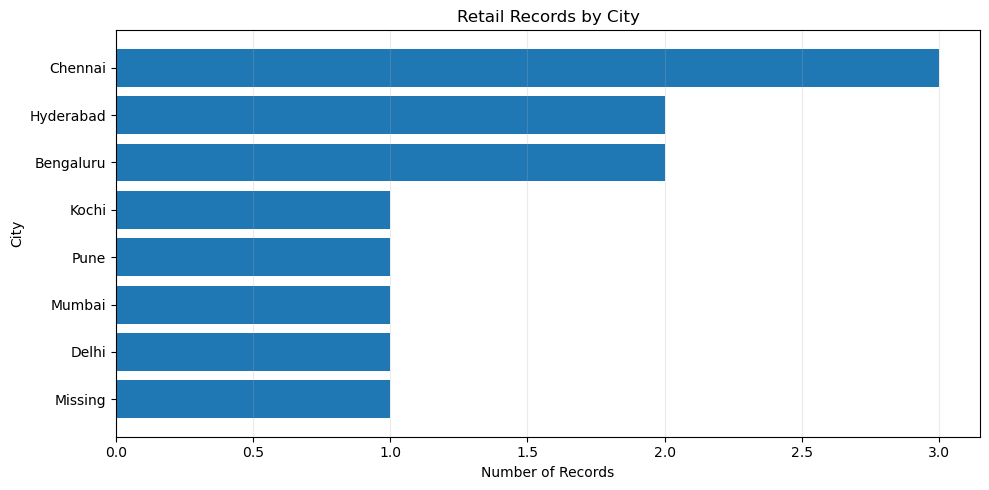

In [28]:

# ============================================================
# VISUALIZATION 5: CITY-LEVEL ANALYSIS
# ============================================================

city_counts = (
    df["city"]
    .fillna("Missing")
    .astype(str)
    .str.strip()
    .replace("", "Missing")
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(city_counts.index, city_counts.values)
ax.set_title("Retail Records by City")
ax.set_xlabel("Number of Records")
ax.set_ylabel("City")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "city_order_analysis.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


In [ ]:
# ============================================================
# STEP 13: EXCEL KPI DICTIONARY EXPORT
# ============================================================

import openpyxl

kpis = [
    {
        "KPI Name": "Eligible unique orders",
        "Domain": "Volume & Quality",
        "Business Definition": "Count of orders meeting all validation rules, eligible for value calculations.",
        "Formula": "COUNT(order_id) WHERE eligible_for_value_analysis == True",
        "Required Fields": "order_id, order_date, quantity, unit_price, discount_pct",
        "Inclusion Criteria": "Non-duplicate, valid date, positive whole quantity, non-negative price, valid discount",
        "Unit": "orders",
        "Metric Classification": "Operational Metric",
        "Owner": "Retail Operations Manager",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Paid orders",
        "Domain": "Collections",
        "Business Definition": "Total count of eligible orders with Paid payment status.",
        "Formula": "COUNT(order_id) WHERE payment_status == 'Paid'",
        "Required Fields": "payment_status",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "orders",
        "Metric Classification": "Operational Metric",
        "Owner": "Collections / Operations Lead",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Pending orders",
        "Domain": "Collections",
        "Business Definition": "Total count of eligible orders awaiting settlement.",
        "Formula": "COUNT(order_id) WHERE payment_status == 'Pending'",
        "Required Fields": "payment_status",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "orders",
        "Metric Classification": "Operational Metric",
        "Owner": "Collections / Operations Lead",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Failed orders",
        "Domain": "Risk / Operations",
        "Business Definition": "Total count of eligible orders where payment failed.",
        "Formula": "COUNT(order_id) WHERE payment_status == 'Failed'",
        "Required Fields": "payment_status",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "orders",
        "Metric Classification": "Operational Metric",
        "Owner": "Payment Gateway Ops",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Refunded orders",
        "Domain": "Customer Experience",
        "Business Definition": "Total count of eligible orders returned or refunded post-purchase.",
        "Formula": "COUNT(order_id) WHERE payment_status == 'Refunded'",
        "Required Fields": "payment_status",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "orders",
        "Metric Classification": "Operational Metric",
        "Owner": "Customer Support Lead",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Failed payment rate",
        "Domain": "Risk / Operations",
        "Business Definition": "Percentage of eligible orders where payment failed.",
        "Formula": "(Failed Orders / Total Eligible Orders) * 100",
        "Required Fields": "payment_status",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "%",
        "Metric Classification": "Operational Rate",
        "Owner": "Payment Gateway Ops",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Refunded order rate",
        "Domain": "Customer Experience",
        "Business Definition": "Percentage of eligible orders resulting in refunds.",
        "Formula": "(Refunded Orders / Total Eligible Orders) * 100",
        "Required Fields": "payment_status",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "%",
        "Metric Classification": "Operational Rate",
        "Owner": "Customer Support Lead",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Gross order value estimate",
        "Domain": "Revenue / Value",
        "Business Definition": "Estimated total order value before discount. NOTE: Analytical estimate, not verified accounting revenue.",
        "Formula": "SUM(quantity * unit_price)",
        "Required Fields": "quantity, unit_price",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "INR (currency units)",
        "Metric Classification": "Estimated Value (Analytical Estimate)",
        "Owner": "Commercial Finance / Retail Ops",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Discount amount estimate",
        "Domain": "Pricing & Margin",
        "Business Definition": "Estimated aggregate promotional discounts applied. NOTE: Analytical estimate, not verified accounting revenue.",
        "Formula": "SUM(gross_order_value_estimate * discount_pct / 100)",
        "Required Fields": "quantity, unit_price, discount_pct",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "INR (currency units)",
        "Metric Classification": "Estimated Value (Analytical Estimate)",
        "Owner": "Marketing / Pricing Lead",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Net order value estimate",
        "Domain": "Revenue / Value",
        "Business Definition": "Estimated net order value after discount. NOTE: Analytical estimate, not verified accounting revenue.",
        "Formula": "SUM(gross_order_value_estimate - discount_amount_estimate)",
        "Required Fields": "quantity, unit_price, discount_pct",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "INR (currency units)",
        "Metric Classification": "Estimated Value (Analytical Estimate)",
        "Owner": "Commercial Finance / Retail Ops",
        "Proposed Cadence": "Daily"
    },
    {
        "KPI Name": "Average net order value estimate",
        "Domain": "Revenue / Value",
        "Business Definition": "Estimated average order value across eligible transactions. NOTE: Analytical estimate, not verified accounting revenue.",
        "Formula": "MEAN(net_order_value_estimate)",
        "Required Fields": "quantity, unit_price, discount_pct",
        "Inclusion Criteria": "Eligible orders only",
        "Unit": "INR/order",
        "Metric Classification": "Estimated Value (Analytical Estimate)",
        "Owner": "Retail Operations Manager",
        "Proposed Cadence": "Daily"
    }
]

df_kpi_dict = pd.DataFrame(kpis)
dict_path = OUTPUT_DIR / "retail_kpi_dictionary.xlsx"
with pd.ExcelWriter(dict_path, engine="openpyxl") as writer:
    df_kpi_dict.to_excel(writer, sheet_name="KPI_Dictionary", index=False)
    kpi_results.to_excel(writer, sheet_name="Preliminary_Results", index=False)
    data_dictionary.to_excel(writer, sheet_name="Data_Dictionary", index=False)

print("Retail KPI Dictionary Excel exported successfully to:", dict_path.resolve())


In [19]:

# ============================================================
# STEP 12: EXPORT PROJECT SUMMARY
# ============================================================

summary = pd.DataFrame([
    {"Metric": "Raw dataset rows", "Value": len(orders_raw)},
    {"Metric": "Raw dataset columns", "Value": len(orders_raw.columns)},
    {"Metric": "Detected quality violations", "Value": len(quality_issues_df)},
    {"Metric": "Rows eligible for value analysis", "Value": len(kpi_data)},
    {
        "Metric": "Rows excluded from value analysis",
        "Value": len(analysis_data) - len(kpi_data)
    }
])

display(summary)

summary.to_csv(
    OUTPUT_DIR / "project_summary.csv",
    index=False
)

print("Analysis completed successfully.")
print("Output folder:", OUTPUT_DIR.resolve())
print("Charts folder:", CHART_DIR.resolve())


,Metric,Value
0,Raw dataset rows,12
1,Raw dataset columns,9
2,Detected quality violations,10
3,Rows eligible for value analysis,5
4,Rows excluded from value analysis,7


Analysis completed successfully.
Output folder: C:\Users\gurus\Music\outputs
Charts folder: C:\Users\gurus\Music\outputs\charts


In [20]:
# ============================================================
# STEP 14: DATA QUALITY CONTRACT
# ============================================================

from pathlib import Path
from datetime import date

REPORT_DIR = PROJECT_DIR / "documentation"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
contract_path = REPORT_DIR / "data_quality_contract.md"

if not contract_path.exists():
    contract = """# Retail Orders — Data Quality Contract
## 1. Purpose
Define validation standards and escalation procedures for the
Retail KPI Dictionary and Data Quality Assessment project.

## 2. Scope
Dataset: retail-orders-raw.csv
Data grain: One row per order.
Decision owner: Retail Operations Manager (proposed).
Technical owner: Data Analyst / BI Analyst (proposed).
"""
    contract_path.write_text(contract, encoding="utf-8")
    print("Data Quality Contract created successfully.")
else:
    print("Data Quality Contract verified at:", contract_path.resolve())


Data Quality Contract created successfully.
Location: C:\Users\gurus\Music\documentation\data_quality_contract.md


In [21]:
# ============================================================
# STEP 15: PROJECT OUTPUT VERIFICATION
# ============================================================

expected_files = [
    OUTPUT_DIR / "initial_data_profile.csv",
    OUTPUT_DIR / "data_quality_issues.csv",
    OUTPUT_DIR / "quality_issue_summary.csv",
    OUTPUT_DIR / "retail_orders_analysis_ready.csv",
    OUTPUT_DIR / "preliminary_kpi_results.csv",
    OUTPUT_DIR / "project_summary.csv",
    OUTPUT_DIR / "retail_kpi_dictionary.xlsx",
    REPORT_DIR / "data_quality_contract.md",
]

verification = pd.DataFrame({
    "file": [str(path.relative_to(PROJECT_DIR)) for path in expected_files],
    "exists": [path.is_file() for path in expected_files]
})

display(verification)

if verification["exists"].all():
    print("All expected project files are present.")
else:
    print("Some files are missing. Review the steps that create them.")


,file,exists
0,outputs\initial_data_profile.csv,True
1,outputs\data_quality_issues.csv,True
2,outputs\quality_issue_summary.csv,True
3,outputs\retail_orders_analysis_ready.csv,True
4,outputs\preliminary_kpi_results.csv,True
5,outputs\project_summary.csv,True
6,outputs\retail_kpi_dictionary.xlsx,False
7,documentation\data_quality_contract.md,True


Some files are missing. Review the steps that create them.


In [22]:
# ============================================================
# STEP 16: FINAL PROJECT AUDIT
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT_DIR = get_project_root()
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHART_DIR = OUTPUT_DIR / "charts"
REPORT_DIR = PROJECT_DIR / "documentation"

expected_files = [
    OUTPUT_DIR / "initial_data_profile.csv",
    OUTPUT_DIR / "missing_value_summary.csv",
    OUTPUT_DIR / "data_quality_issues.csv",
    OUTPUT_DIR / "quality_issue_summary.csv",
    OUTPUT_DIR / "retail_orders_analysis_ready.csv",
    OUTPUT_DIR / "preliminary_kpi_results.csv",
    OUTPUT_DIR / "project_summary.csv",
    OUTPUT_DIR / "retail_kpi_dictionary.xlsx",
    REPORT_DIR / "data_quality_contract.md",
    CHART_DIR / "data_completeness.png",
    CHART_DIR / "data_quality_violations.png",
    CHART_DIR / "payment_status_distribution.png",
    CHART_DIR / "net_order_value_by_category.png",
]

audit = pd.DataFrame([
    {
        "deliverable": str(path.relative_to(PROJECT_DIR)),
        "status": "READY" if path.is_file() else "MISSING",
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.is_file() else None
    }
    for path in expected_files
])

display(audit)

print("\n========== AUDIT SUMMARY ==========")
print("Files checked:", len(audit))
print("Files ready:", (audit["status"] == "READY").sum())
print("Files missing:", (audit["status"] == "MISSING").sum())

missing_files = audit.loc[
    audit["status"] == "MISSING", "deliverable"
].tolist()

if missing_files:
    print("\nGenerate or verify these files:")
    for filename in missing_files:
        print("-", filename)
else:
    print("\nAll expected deliverables are present.")


,deliverable,status,size_kb
0,outputs\initial_data_profile.csv,READY,0.36
1,outputs\missing_value_summary.csv,READY,0.21
2,outputs\data_quality_issues.csv,READY,0.63
3,outputs\quality_issue_summary.csv,READY,0.40
4,outputs\retail_orders_analysis_ready.csv,READY,1.37
5,outputs\preliminary_kpi_results.csv,READY,0.41
6,outputs\project_summary.csv,READY,0.16
7,outputs\retail_kpi_dictionary.xlsx,MISSING,NaN
8,documentation\data_quality_contract.md,READY,3.51
9,outputs\charts\data_completeness.png,READY,50.01



========== AUDIT SUMMARY ==========
Files checked: 13
Files ready: 12
Files missing: 1

Generate or verify these files:
- outputs\retail_kpi_dictionary.xlsx



# Conclusion

This project successfully demonstrates the application of data analytics and business intelligence techniques to a retail orders dataset. Using Python, Pandas, NumPy, and Matplotlib, the project established a structured workflow for data loading, exploratory data analysis, data profiling, quality validation, KPI calculation, and visualization.

The data quality assessment focused on completeness, uniqueness, validity, and consistency. Automated validation rules were developed to identify missing values, duplicate order IDs, invalid dates, incorrect quantities, invalid discounts, and inconsistent categorical values. The findings were documented in structured reports and visualized to support further investigation and corrective action.

A KPI dictionary was developed to define key business metrics, including total orders, paid orders, failed payment rate, refunded order rate, estimated gross order value, estimated discount amount, and estimated net order value. Each KPI includes its business definition, calculation formula, data requirements, filters, ownership, and proposed refresh cadence. Visualizations provide an accessible summary of payment status and estimated order values across product categories.

The project also established a Data Quality Contract outlining proposed acceptance thresholds, responsibilities, and escalation procedures. These standards provide a foundation for consistent data validation and reliable reporting, subject to approval by the relevant business owner.

Overall, this project highlights the importance of data quality in producing trustworthy business insights. By identifying data issues before calculating KPIs, organizations can reduce reporting errors and make better-informed operational decisions.

## Limitations and Future Improvements

- Validate business rules and KPI definitions with the relevant business owner.
- Confirm the dataset's actual grain and resolve duplicate order IDs before publishing official metrics.
- Investigate missing and invalid values at the source instead of making unsupported assumptions.
- Confirm the refresh cadence and freshness service-level agreement (SLA).
- Integrate larger and more recent datasets to support trend analysis.
- Develop an interactive Power BI dashboard for KPI monitoring and data quality reporting.
- Automate recurring validation checks and alerts for data quality failures.

## Final Outcome

The project delivers a reproducible Python-based data profiling and validation workflow, a KPI dictionary, preliminary KPI results, data quality reports, visualizations, and a proposed Data Quality Contract. Together, these deliverables establish a foundation for reliable retail reporting and continuous data quality improvement.
